In [1]:
!wget 'https://raw.githubusercontent.com/nursace/ai-framework-slides/main/data/campus-commute-late.csv' -O campus-commute-late.csv

--2026-10-22 14:08:15--  https://raw.githubusercontent.com/nursace/ai-framework-slides/main/data/campus-commute-late.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 18994 (19K) [text/plain]
Saving to: ‘campus-commute-late.csv’

campus-commute-late 100%[===================>]  18.55K  --.-KB/s    in 0.001s  

2026-10-22 14:08:16 (16.9 MB/s) - ‘campus-commute-late.csv’ saved [18994/18994]



In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

df = pd.read_csv('campus-commute-late.csv')

numeric_features = [
    'distance_km',
    'leave_hour',
    'buffer_minutes',
    'sleep_hours',
    'raining',
    'temperature_c',
    'traffic_index',
    'backpack_kg',
    'phone_battery',
    'woke_late'
]

X_mode = pd.get_dummies(
    df['commute_mode'],
    prefix='mode',
    dtype=int
)

X = pd.concat([df[numeric_features], X_mode], axis=1)
y = df['is_late']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print('размер таблицы:', df.shape)
print('обучающая выборка:', X_train.shape)
print('тестовая выборка:', X_test.shape)

размер таблицы: (380, 14)
обучающая выборка: (285, 14)
тестовая выборка: (95, 14)


In [3]:
def create_knn(k=5, scaling=True):
    steps = [
        ('imputer', SimpleImputer(strategy='median'))
    ]

    if scaling:
        steps.append(('scaler', StandardScaler()))

    steps.append(
        ('knn', KNeighborsClassifier(n_neighbors=k))
    )

    return Pipeline(steps)

In [4]:
knn_plain = create_knn(k=5, scaling=False)
knn_plain.fit(X_train, y_train)

pred_plain = knn_plain.predict(X_test)
accuracy_plain = accuracy_score(y_test, pred_plain)

knn_scaled = create_knn(k=5, scaling=True)
knn_scaled.fit(X_train, y_train)

pred_scaled = knn_scaled.predict(X_test)
accuracy_scaled = accuracy_score(y_test, pred_scaled)

print(f'Accuracy без Scaling: {accuracy_plain:.6f}')
print(f'Accuracy со Scaling:  {accuracy_scaled:.6f}')

Accuracy без Scaling: 0.589474
Accuracy со Scaling:  0.715789


[[34 12]
 [15 34]]


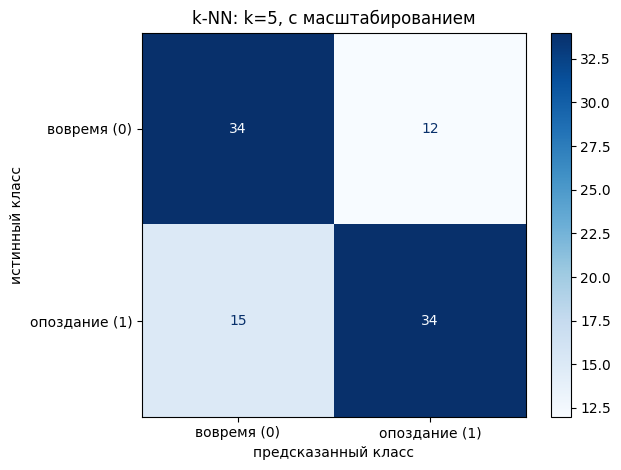

In [5]:
cm = confusion_matrix(y_test, pred_scaled, labels=[0, 1])

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['вовремя (0)', 'опоздание (1)']
)

disp.plot(cmap='Blues')
plt.title('k-NN: k=5, с масштабированием')
plt.xlabel('предсказанный класс')
plt.ylabel('истинный класс')
plt.tight_layout()
plt.show()

1

 k  test_accuracy
 1       0.642105
 3       0.663158
 5       0.715789
 7       0.778947
 9       0.789474
11       0.778947
15       0.778947
21       0.747368

Лучшие k среди проверенных: [9]
максимальная test accuracy: 0.789474


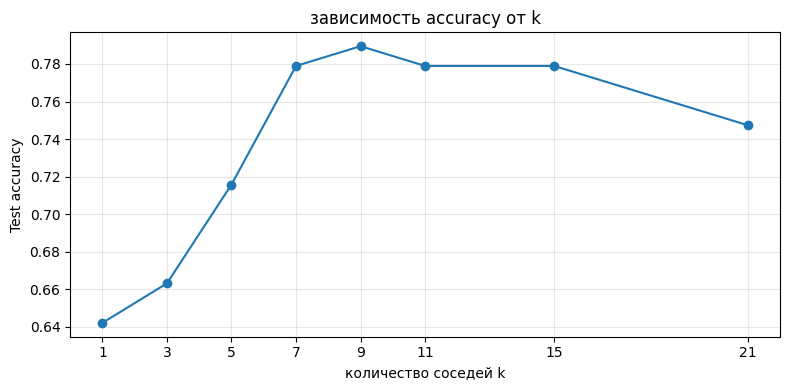

In [6]:
k_values = [1, 3, 5, 7, 9, 11, 15, 21]
accuracies = []

for k in k_values:
    model = create_knn(k=k)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, predictions))

results = pd.DataFrame({
    'k': k_values,
    'test_accuracy': accuracies
})

print(results.round(6).to_string(index=False))

best_accuracy = results['test_accuracy'].max()
best_k = results.loc[
    results['test_accuracy'] == best_accuracy, 'k'
].tolist()

print('\nЛучшие k среди проверенных:', best_k)
print(f'максимальная test accuracy: {best_accuracy:.6f}')

plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o')

plt.xticks(k_values)
plt.xlabel('количество соседей k')
plt.ylabel('Test accuracy')
plt.title('зависимость accuracy от k')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

А

In [7]:
X_day = pd.get_dummies(
    df['day_of_week'],
    prefix='day',
    dtype=int
)

X_with_day = pd.concat([X, X_day], axis=1)

X_train_day, X_test_day, y_train_day, y_test_day = (
    train_test_split(
        X_with_day, y,
        test_size=0.25,
        random_state=42,
        stratify=y
    )
)

knn_day = create_knn(k=5)
knn_day.fit(X_train_day, y_train_day)

pred_day = knn_day.predict(X_test_day)
accuracy_day = accuracy_score(y_test_day, pred_day)

print(f'Accuracy без дня недели: {accuracy_scaled:.6f}')
print(f'Accuracy с днем недели:  {accuracy_day:.6f}')
print(f'изменение: {accuracy_day - accuracy_scaled:+.6f}')

Accuracy без дня недели: 0.715789
Accuracy с днем недели:  0.652632
изменение: -0.063158


В

In [8]:
two_features = ['distance_km', 'buffer_minutes']

knn_two = create_knn(k=5)

knn_two.fit(
    X_train[two_features],
    y_train
)

pred_two = knn_two.predict(X_test[two_features])
accuracy_two = accuracy_score(y_test, pred_two)

print(f'Accuracy полной модели: {accuracy_scaled:.6f}')
print(f'Accuracy двух признаков: {accuracy_two:.6f}')
print(f'изменение: {accuracy_two - accuracy_scaled:+.6f}')

Accuracy полной модели: 0.715789
Accuracy двух признаков: 0.652632
изменение: -0.063158


При использовании только расстояния и запаса времени accuracy снизилась с 71.58% до 65.26%. Эти признаки не учитывают, как студент добирается до кампуса и насколько загружена дорога. Например, одно и то же расстояние пешком и на велосипеде требует разного времени. На этой тестовой выборке полная модель дала более точный результат.